<a href="https://colab.research.google.com/github/JariusF10-8/bt4222/blob/main/notebooks/Categorical_Text_Features.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 5.3 Categorical Features and 5.4 Text / Corpus / Media

This notebook reproduces every number, table and figure in Sections 5.3 and 5.4 of the interim report.

**Scope**
- All descriptive statistics use `MINDsmall_train` (9 to 14 November 2019), the same file used in Sections 5.1 and 5.2.
- Unseen value rates and out of vocabulary rates use the temporal partitions from Section 3.4: training = 9 to 12 November, validation = 13 to 14 November. Anything learned (a category list, a vocabulary) is fitted on the training partition only and then checked against validation.
- `MINDsmall_dev` (our test set) is not loaded here.

**Loader.** Files are read with quoting disabled (`csv.QUOTE_NONE`), as in `Dataset_Overview.ipynb`. Section 1 below shows why: pandas' default quote handling merges fields in 4 news rows and strips quotation marks from 48 titles.

Run all cells from top to bottom. Locally, with the repository cloned, the data folder is `../MINDsmall_train`. In Colab, the first code cell mounts Google Drive and reads the group's shared `MINDsmall_train` folder instead.

In [1]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

In [2]:
import csv
import json
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 90)

DATA_DIRS = [
    Path("../MINDsmall_train"),
    Path("/content/drive/MyDrive/BT4222 Group Project/Microsoft MIND/MINDsmall_train"),
]
DATA_DIR = next(p for p in DATA_DIRS if (p / "news.tsv").is_file())
FIG_DIR = Path("../figures") if DATA_DIR == DATA_DIRS[0] else Path("figures")
FIG_DIR.mkdir(exist_ok=True)

VALIDATION_START = pd.Timestamp("2019-11-13")
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
print("Data folder:", DATA_DIR)

Data folder: ../MINDsmall_train


## 0. Load and parse

One behaviour row is one impression. Candidates are expanded to one row per exposed article with its 0/1 click label. Entity JSON is parsed into lists; an empty list `[]` means the linker found no entity and is kept as a valid value.

In [3]:
BEHAVIOR_COLUMNS = ["impression_id", "user_id", "time", "history", "impressions"]
NEWS_COLUMNS = ["news_id", "category", "subcategory", "title", "abstract", "url", "title_entities", "abstract_entities"]


def read_tsv(path, columns, literal_quotes=True):
    options = dict(sep="\t", header=None, names=columns, encoding="utf-8")
    if literal_quotes:
        options.update(dtype="string", keep_default_na=False, na_values=[""], quoting=csv.QUOTE_NONE)
    else:
        options.update(dtype=str)
    return pd.read_csv(path, **options)


behaviors = read_tsv(DATA_DIR / "behaviors.tsv", BEHAVIOR_COLUMNS)
news = read_tsv(DATA_DIR / "news.tsv", NEWS_COLUMNS)

behaviors["timestamp"] = pd.to_datetime(behaviors["time"], format="%m/%d/%Y %I:%M:%S %p")
behaviors["history_ids"] = behaviors["history"].fillna("").str.split()
behaviors["partition"] = np.where(behaviors["timestamp"] < VALIDATION_START, "train", "validation")
behaviors["hour_of_day"] = behaviors["timestamp"].dt.hour
behaviors["day_of_week"] = behaviors["timestamp"].dt.day_name()

tokens = behaviors["impressions"].str.split()
candidates = pd.DataFrame({
    "impression_id": behaviors["impression_id"].repeat(tokens.str.len()).to_numpy(),
    "token": np.concatenate(tokens.to_numpy()),
})
candidates["news_id"] = candidates["token"].str.rsplit("-", n=1).str[0]
candidates["label"] = candidates["token"].str.rsplit("-", n=1).str[1].astype(int)
candidates = candidates.drop(columns="token").merge(
    behaviors[["impression_id", "user_id", "partition"]],
    on="impression_id", how="left", validate="many_to_one",
)

for field in ["title", "abstract"]:
    news[f"{field}_entity_list"] = news[f"{field}_entities"].apply(
        lambda s: json.loads(s) if isinstance(s, str) and s.strip() else []
    )

news_meta = news.set_index("news_id")
candidates["category"] = candidates["news_id"].map(news_meta["category"])
candidates["subcategory"] = candidates["news_id"].map(news_meta["subcategory"])

entities = pd.DataFrame([
    {
        "news_id": news_id,
        "field": field,
        "type": e["Type"],
        "entity_id": e["WikidataId"],
        "label": e["Label"],
        "confidence": e["Confidence"],
        "offsets": e["OccurrenceOffsets"],
        "surface_forms": e["SurfaceForms"],
    }
    for field in ["title", "abstract"]
    for news_id, entity_list in zip(news["news_id"], news[f"{field}_entity_list"])
    for e in entity_list
])

print("Impressions:", len(behaviors), "| Candidate exposures:", len(candidates), "| Clicks:", candidates["label"].sum())
print("Articles:", len(news), "| Entity mentions:", len(entities))
print("Missing values in news.tsv:")
display(news[NEWS_COLUMNS].isna().sum().to_frame("missing"))

Impressions: 156965 | Candidate exposures: 5843444 | Clicks: 236344
Articles: 51282 | Entity mentions: 155266
Missing values in news.tsv:


,missing
news_id,0
category,0
subcategory,0
title,0
abstract,2666
url,0
title_entities,0
abstract_entities,0


## 1. Why quoting is disabled

The default pandas reader treats `"` as a quote character. MIND fields are tab separated and contain literal quotation marks, so a field that starts with `"` swallows the following tab separated fields. This compares the two readers on the same file.

In [4]:
news_default = read_tsv(DATA_DIR / "news.tsv", NEWS_COLUMNS, literal_quotes=False).set_index("news_id")
literal = news_meta[NEWS_COLUMNS[1:]].astype(object)
changed = news_default[NEWS_COLUMNS[1:]].fillna("<NA>").ne(literal.fillna("<NA>"))
display(changed.sum().rename("rows that differ from literal reading").to_frame())

shifted = news_default.index[~news_default["url"].fillna("").str.startswith("https://")]
print("Rows whose columns are shifted by the default reader:", list(shifted))
print("Entity fields read as missing by the default reader:",
      int(news_default["title_entities"].isna().sum()), "title,",
      int(news_default["abstract_entities"].isna().sum()), "abstract")


def aligned_offsets(texts, entity_lists):
    ok = total = 0
    for text, entity_list in zip(texts, entity_lists):
        for e in entity_list:
            for offset, surface in zip(e["OccurrenceOffsets"], e["SurfaceForms"]):
                total += 1
                ok += isinstance(text, str) and text[offset:offset + len(surface)] == surface
    return ok, total


quote_titles = changed.index[changed["title"]]
ok, total = aligned_offsets(news_default.loc[quote_titles, "title"], news_meta.loc[quote_titles, "title_entity_list"])
print(f"Titles altered by the default reader: {len(quote_titles)}; their entity offsets that still align: {ok} of {total}")
for field in ["title", "abstract"]:
    ok, total = aligned_offsets(news[field], news[f"{field}_entity_list"])
    print(f"Literal reader, {field}: {ok} of {total} offset and surface form pairs align ({ok / total:.2%})")
print("Longest title in words, default vs literal:",
      news_default["title"].str.split().str.len().max(), "vs", news["title"].str.split().str.len().max())

,rows that differ from literal reading
category,0
subcategory,0
title,48
abstract,520
url,4
title_entities,3
abstract_entities,4


Rows whose columns are shifted by the default reader: ['N49553', 'N20922', 'N18259', 'N16590']
Entity fields read as missing by the default reader: 3 title, 4 abstract
Titles altered by the default reader: 48; their entity offsets that still align: 0 of 47
Literal reader, title: 60360 of 60360 offset and surface form pairs align (100.00%)
Literal reader, abstract: 110273 of 110273 offset and surface form pairs align (100.00%)


Longest title in words, default vs literal: 57 vs 48


## 2. Temporal partitions used for unseen value checks

Articles "seen in training" are all articles referenced (in a history or as a candidate) by training partition impressions, matching the metadata retention rule in Section 3.3.

In [5]:
train_events = behaviors[behaviors["partition"] == "train"]
validation_events = behaviors[behaviors["partition"] == "validation"]
train_candidates = candidates[candidates["partition"] == "train"]
validation_candidates = candidates[candidates["partition"] == "validation"]


def referenced_articles(events, event_candidates):
    return set(event_candidates["news_id"]) | {a for history in events["history_ids"] for a in history}


train_articles = referenced_articles(train_events, train_candidates)
validation_articles = referenced_articles(validation_events, validation_candidates)
validation_only_articles = validation_articles - train_articles

print("Articles referenced by training impressions:", len(train_articles))
print("Articles referenced by validation impressions:", len(validation_articles))
print("Validation only articles:", len(validation_only_articles))
print(f"Validation exposures on validation only articles: {validation_candidates['news_id'].isin(validation_only_articles).mean():.2%}")

Articles referenced by training impressions: 43370
Articles referenced by validation impressions: 38421
Validation only articles: 7912
Validation exposures on validation only articles: 48.65%


# 5.3 Categorical Features

## 5.3.1 Summary table (Table 13)

**Unseen in validation** = share of validation rows whose value never occurs in the training partition. Rows are impressions for user and time features, and candidate exposures for article and entity features.

In [6]:
def top_values(series, k=3, fmt=str):
    shares = series.value_counts(normalize=True).head(k) * 100
    return ", ".join(f"{fmt(v)} ({s:.1f}%)" for v, s in shares.items())


def unseen(values, seen):
    return f"{(~pd.Series(values).isin(set(seen))).mean():.2%}"


train_meta = news_meta.loc[sorted(train_articles)]
train_entities = entities[entities["news_id"].isin(train_articles)]
validation_entity_mentions = validation_candidates[["news_id"]].merge(
    entities[["news_id", "type", "entity_id"]], on="news_id", how="inner"
)
impressions_per_user = behaviors["user_id"].value_counts()
history_articles = {a for history in behaviors["history_ids"] for a in history}
candidate_articles = set(candidates["news_id"])
entity_articles = entities.drop_duplicates(["news_id", "entity_id"])["entity_id"].value_counts()
entity_labels = entities.drop_duplicates("entity_id").set_index("entity_id")["label"]

categorical_summary = pd.DataFrame([
    {
        "Feature": "category",
        "Level": "Article",
        "Distinct values": news["category"].nunique(),
        "Representative values (share)": top_values(news["category"]),
        "Missing": int(news["category"].isna().sum()),
        "Unseen in validation": unseen(validation_candidates["category"], train_meta["category"]),
    },
    {
        "Feature": "subcategory",
        "Level": "Article",
        "Distinct values": news["subcategory"].nunique(),
        "Representative values (share)": top_values(news["subcategory"]),
        "Missing": int(news["subcategory"].isna().sum()),
        "Unseen in validation": unseen(validation_candidates["subcategory"], train_meta["subcategory"]),
    },
    {
        "Feature": "entity_type",
        "Level": "Entity mention",
        "Distinct values": entities["type"].nunique(),
        "Representative values (share)": top_values(entities["type"]),
        "Missing": int(entities["type"].isna().sum()),
        "Unseen in validation": unseen(validation_entity_mentions["type"], train_entities["type"]),
    },
    {
        "Feature": "entity_id (WikidataId)",
        "Level": "Entity mention",
        "Distinct values": entities["entity_id"].nunique(),
        "Representative values (share)": ", ".join(
            f"{entity_labels[e]} ({n:,} articles)" for e, n in entity_articles.head(3).items()
        ),
        "Missing": int(entities["entity_id"].isna().sum()),
        "Unseen in validation": unseen(validation_entity_mentions["entity_id"], train_entities["entity_id"]),
    },
    {
        "Feature": "user_id",
        "Level": "Impression",
        "Distinct values": behaviors["user_id"].nunique(),
        "Representative values (share)": f"median {impressions_per_user.median():.0f} impressions per user, max {impressions_per_user.max()}",
        "Missing": int(behaviors["user_id"].isna().sum()),
        "Unseen in validation": unseen(validation_events["user_id"], train_events["user_id"]),
    },
    {
        "Feature": "news_id (candidate)",
        "Level": "Exposure",
        "Distinct values": len(candidate_articles),
        "Representative values (share)": f"{len(candidate_articles):,} as candidates, {len(history_articles):,} in histories, {len(candidate_articles & history_articles):,} in both",
        "Missing": int(candidates["news_id"].isna().sum()),
        "Unseen in validation": unseen(validation_candidates["news_id"], train_candidates["news_id"]),
    },
    {
        "Feature": "hour_of_day (derived)",
        "Level": "Impression",
        "Distinct values": behaviors["hour_of_day"].nunique(),
        "Representative values (share)": top_values(behaviors["hour_of_day"], fmt=lambda h: f"{h:02d}:00"),
        "Missing": int(behaviors["hour_of_day"].isna().sum()),
        "Unseen in validation": unseen(validation_events["hour_of_day"], train_events["hour_of_day"]),
    },
    {
        "Feature": "day_of_week (derived)",
        "Level": "Impression",
        "Distinct values": behaviors["day_of_week"].nunique(),
        "Representative values (share)": top_values(behaviors["day_of_week"]),
        "Missing": int(behaviors["day_of_week"].isna().sum()),
        "Unseen in validation": unseen(validation_events["day_of_week"], train_events["day_of_week"]),
    },
])
display(categorical_summary)
print(f"Validation clicks on articles never shown as candidates in training: "
      f"{(~validation_candidates.loc[validation_candidates['label'] == 1, 'news_id'].isin(set(train_candidates['news_id']))).mean():.2%}")
print("Validation users not seen in training:",
      len(set(validation_events["user_id"]) - set(train_events["user_id"])), "of", validation_events["user_id"].nunique())
print(f"Distinct entities in validation candidates that are new: "
      f"{len(set(validation_entity_mentions['entity_id']) - set(train_entities['entity_id'])) / validation_entity_mentions['entity_id'].nunique():.2%}")
print(f"Users with a single impression: {(impressions_per_user == 1).mean():.2%}")

,Feature,Level,Distinct values,Representative values (share),Missing,Unseen in validation
0,category,Article,17,"news (30.8%), sports (28.3%), finance (6.1%)",0,0.00%
1,subcategory,Article,264,"newsus (12.8%), football_nfl (10.6%), newspolitics (5.5%)",0,0.14%
2,entity_type,Entity mention,22,"O (24.9%), G (23.9%), P (22.4%)",0,0.00%
3,entity_id (WikidataId),Entity mention,27761,"Donald Trump (2,241 articles), United States (1,306 articles), National Football Leagu...",0,8.67%
4,user_id,Impression,50000,"median 2 impressions per user, max 62",0,24.51%
5,news_id (candidate),Exposure,20288,"20,288 as candidates, 33,195 in histories, 2,201 in both",0,50.34%
6,hour_of_day (derived),Impression,24,"11:00 (8.0%), 08:00 (8.0%), 10:00 (7.8%)",0,0.00%
7,day_of_week (derived),Impression,6,"Tuesday (21.4%), Monday (20.9%), Wednesday (20.1%)",0,100.00%


Validation clicks on articles never shown as candidates in training: 56.11%
Validation users not seen in training: 9852 of 31664


Distinct entities in validation candidates that are new: 32.18%
Users with a single impression: 32.77%


## 5.3.2 Category: catalogue share versus exposure share versus clicks (Figure 6)

In [7]:
overall_ctr = candidates["label"].mean() * 100
by_category = candidates.groupby("category").agg(exposures=("label", "size"), clicks=("label", "sum"))
category_table = pd.DataFrame({
    "Articles": news["category"].value_counts(),
    "Subcategories": news.groupby("category")["subcategory"].nunique(),
}).join(by_category).fillna(0)
category_table["Share of articles (%)"] = category_table["Articles"] / category_table["Articles"].sum() * 100
category_table["Share of exposures (%)"] = category_table["exposures"] / category_table["exposures"].sum() * 100
category_table["Share of clicks (%)"] = category_table["clicks"] / category_table["clicks"].sum() * 100
category_table["CTR (%)"] = np.where(category_table["exposures"] > 0, category_table["clicks"] / category_table["exposures"].replace(0, np.nan) * 100, np.nan)
category_table = category_table.sort_values("Articles", ascending=False).astype({"exposures": int, "clicks": int})
display(category_table.round(2))
print(f"Overall CTR: {overall_ctr:.2f}%")
print("Articles ever shown as candidates, by rare category:",
      candidates.drop_duplicates("news_id").query("category in ['kids', 'middleeast', 'northamerica']")["category"].value_counts().to_dict())

,Articles,Subcategories,exposures,clicks,Share of articles (%),Share of exposures (%),Share of clicks (%),CTR (%)
category,,,,,,,,
news,15774,33,1591038,69408,30.76,27.23,29.37,4.36
sports,14510,31,592226,28181,28.29,10.13,11.92,4.76
finance,3107,32,564671,20597,6.06,9.66,8.71,3.65
foodanddrink,2551,16,369382,10883,4.97,6.32,4.60,2.95
lifestyle,2479,47,655440,26584,4.83,11.22,11.25,4.06
travel,2350,14,315101,8304,4.58,5.39,3.51,2.64
video,2068,14,93744,4262,4.03,1.60,1.80,4.55
weather,2048,2,88646,4582,3.99,1.52,1.94,5.17
health,1885,20,304088,10863,3.68,5.20,4.60,3.57


Overall CTR: 4.04%
Articles ever shown as candidates, by rare category: {'kids': 11, 'northamerica': 1}


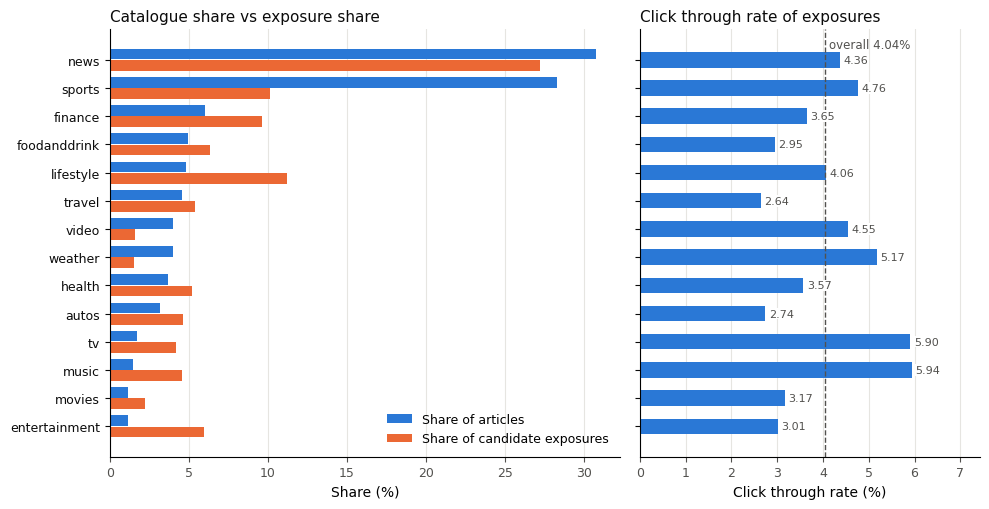

In [8]:
plot_data = category_table[category_table["Articles"] >= 100].sort_values("Share of articles (%)")
y = np.arange(len(plot_data))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5.2), sharey=True, gridspec_kw={"width_ratios": [1.5, 1]})
ax1.barh(y + 0.2, plot_data["Share of articles (%)"], height=0.38, color=BLUE, label="Share of articles")
ax1.barh(y - 0.2, plot_data["Share of exposures (%)"], height=0.38, color=ORANGE, label="Share of candidate exposures")
ax1.set_yticks(y, plot_data.index)
ax1.set_xlabel("Share (%)")
ax1.set_title("Catalogue share vs exposure share", loc="left", fontsize=11, color=INK)
ax1.legend(frameon=False, loc="lower right", fontsize=9)
ax2.barh(y, plot_data["CTR (%)"], height=0.55, color=BLUE)
ax2.axvline(overall_ctr, color=MUTED, linestyle="--", linewidth=1)
ax2.text(overall_ctr + 0.08, len(plot_data) - 0.6, f"overall {overall_ctr:.2f}%", color=MUTED, fontsize=8.5)
for yi, v in zip(y, plot_data["CTR (%)"]):
    ax2.text(v + 0.08, yi, f"{v:.2f}", va="center", fontsize=8, color=MUTED,
             bbox=dict(facecolor="white", edgecolor="none", pad=0.6))
ax2.set_xlabel("Click through rate (%)")
ax2.set_xlim(0, plot_data["CTR (%)"].max() * 1.25)
ax2.set_title("Click through rate of exposures", loc="left", fontsize=11, color=INK)
for ax in (ax1, ax2):
    ax.grid(axis="x", color="#e6e5e1", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.tick_params(axis="y", colors=INK)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_5_3_category_share_ctr.png", dpi=200, bbox_inches="tight")
plt.show()

## 5.3.3 Subcategory: long tail and hierarchy check

In [9]:
subcategory_counts = news["subcategory"].value_counts()
print("Distinct subcategories:", len(subcategory_counts))
print("Distinct (category, subcategory) pairs:", len(news[["category", "subcategory"]].drop_duplicates()))
print("Median articles per subcategory:", subcategory_counts.median())
for k in [5, 10]:
    print(f"Subcategories with fewer than {k} articles: {(subcategory_counts < k).sum()}")
print(f"Share of articles in the 10 largest subcategories: {subcategory_counts.head(10).sum() / len(news):.2%}")
print("Subcategories ever shown as candidates:", candidates["subcategory"].nunique())

parents = news.groupby("subcategory")["category"].nunique()
shared = parents[parents > 1].index
print("Subcategory names used under more than one category:", len(shared))
display(
    news[news["subcategory"].isin(shared)]
    .groupby(["subcategory", "category"]).size().rename("articles").to_frame()
)

Distinct subcategories: 264
Distinct (category, subcategory) pairs: 283
Median articles per subcategory: 15.5
Subcategories with fewer than 5 articles: 91
Subcategories with fewer than 10 articles: 112
Share of articles in the 10 largest subcategories: 52.50%


Subcategories ever shown as candidates: 214
Subcategory names used under more than one category: 13


articles
subcategory        category               
animals            kids                  2
                   video               257
causes             finance               3
                   health               11
                   lifestyle            11
                   news                  2
holidays           lifestyle             2
                   travel                2
humor              entertainment         9
                   music                 1
                   tv                   15
news               entertainment        17
                   video              1168
newstrends         foodanddrink       1175
                   travel                1
personalfinance    finance             118
                   news                  2
pregnancyparenting health                8
                   lifestyle             1
recipes            foodanddrink        461
                   health                2
science            kids                  1
                   video               134
topnews            music                 1
                   tv                    1
video              entertainment        28
                   health               11
                   kids                  5
                   travel               50
voices             health               51
                   lifestyle            86
                   travel                6

## 5.3.4 Entity type

`Type` is a single letter code that the MIND documentation does not define. The interpretation column is ours, based on the most frequent labels within each code (printed below). CTR columns compare candidate exposures whose **title** contains at least one entity of that type with all other exposures.

In [10]:
TYPE_MEANING = {
    "O": "Organisation", "G": "Geopolitical place", "P": "Person", "U": "Other or unclassified",
    "C": "General concept", "F": "Facility", "N": "Newly created entity (mixed)", "M": "Media outlet",
    "S": "Structure or infrastructure", "W": "Creative work or show", "E": "Event", "L": "Natural or continental place",
    "B": "Governing body or award", "H": "Holiday", "V": "Vehicle model", "K": "Office or position",
    "J": "Product or brand", "Y": "Nationality or ethnic group", "R": "Fictional character",
    "Q": "Spacecraft or instrument", "A": "Animal breed", "I": "Individual animal",
}

title_types = (
    entities[entities["field"] == "title"]
    .groupby(["news_id", "type"]).size().unstack(fill_value=0).gt(0)
    .reindex(news["news_id"], fill_value=False)
)
exposure_types = candidates[["news_id", "label"]].join(title_types, on="news_id")

rows = []
for code_, group in entities.groupby("type"):
    in_title = exposure_types[code_]
    rows.append({
        "Code": code_,
        "Interpretation": TYPE_MEANING[code_],
        "Mentions": len(group),
        "Share of mentions (%)": len(group) / len(entities) * 100,
        "Distinct entities": group["entity_id"].nunique(),
        "Example labels": ", ".join(group["label"].value_counts().head(3).index),
        "Share of exposures with type in title (%)": in_title.mean() * 100,
        "CTR with type in title (%)": exposure_types.loc[in_title, "label"].mean() * 100,
        "CTR otherwise (%)": exposure_types.loc[~in_title, "label"].mean() * 100,
        "Mean confidence": group["confidence"].mean(),
    })
entity_type_table = pd.DataFrame(rows).sort_values("Mentions", ascending=False)
display(entity_type_table.round(3))

no_title_entity = ~title_types.any(axis=1).reindex(exposure_types["news_id"]).to_numpy()
print(f"Exposures whose title has no linked entity: {no_title_entity.mean():.2%}; CTR {exposure_types.loc[no_title_entity, 'label'].mean():.2%} "
      f"vs {exposure_types.loc[~no_title_entity, 'label'].mean():.2%} otherwise")
print(f"Share of mentions in the three largest types: {entity_type_table['Mentions'].head(3).sum() / len(entities):.2%}")
other_codes = sorted(set(entities["type"]) - set(entity_type_table["Code"].head(11)))
other_mentions = entities[entities["type"].isin(other_codes)]
other_in_title = exposure_types[other_codes].any(axis=1)
print(f"Remaining {len(other_codes)} codes {other_codes}: {len(other_mentions) / len(entities):.2%} of mentions, "
      f"{other_mentions['entity_id'].nunique()} distinct entities, CTR with any in title "
      f"{exposure_types.loc[other_in_title, 'label'].mean():.2%} vs {exposure_types.loc[~other_in_title, 'label'].mean():.2%}")
print("Entities recorded with more than one type:", int((entities.groupby("entity_id")["type"].nunique() > 1).sum()))
print("Confidence: min", entities["confidence"].min(), "| median", entities["confidence"].median(),
      "| share at least 0.99", f"{(entities['confidence'] >= 0.99).mean():.2%}")

wikidata_number = entities.drop_duplicates("entity_id").assign(q=lambda d: d["entity_id"].str[1:].astype(int))
print("Median Wikidata Q number by type (higher means a more recently created Wikidata item):")
print(wikidata_number.groupby("type")["q"].median().sort_values().astype(int).to_dict())

for field in ["title", "abstract"]:
    empty = news[f"{field}_entity_list"].str.len().eq(0)
    print(f"Articles with an empty {field} entity list: {empty.sum()} ({empty.mean():.2%})")
no_entity = news["title_entity_list"].str.len().eq(0) & news["abstract_entity_list"].str.len().eq(0)
print(f"Articles with no entity in either field: {no_entity.sum()} ({no_entity.mean():.2%})")

,Code,Interpretation,Mentions,Share of mentions (%),Distinct entities,Example labels,Share of exposures with type in title (%),CTR with type in title (%),CTR otherwise (%),Mean confidence
13,O,Organisation,38695,24.922,3919,"National Football League, New England Patriots, Houston Astros",16.311,4.729,3.911,0.994
5,G,Geopolitical place,37185,23.949,4402,"United States, California, Ukraine",12.092,4.306,4.009,0.990
14,P,Person,34813,22.422,6221,"Donald Trump, Joe Biden, Tom Brady",23.944,5.077,3.720,0.997
18,U,Other or unclassified,10011,6.448,3097,"Islamic State of Iraq and the Levant, College Football Playoff, Presidency of Donald T...",7.475,3.590,4.081,0.992
2,C,General concept,6614,4.260,2385,"Sport utility vehicle, Sheriff, Forward (association football)",7.332,3.177,4.113,0.990
4,F,Facility,4854,3.126,1658,"White House, LSU Tigers football, Michigan Wolverines football",1.432,8.354,3.982,0.989
12,N,Newly created entity (mixed),4604,2.965,1252,"Storyful, Meghan, Duchess of Sussex, Patrick Mahomes",5.420,4.562,4.015,0.994
11,M,Media outlet,3883,2.501,716,"CNN, Taste of Home, ESPN",1.587,3.054,4.061,0.995
17,S,Structure or infrastructure,3222,2.075,1198,"Interstate 95, Wall Street, Interstate 75",0.257,2.574,4.048,0.995
20,W,Creative work or show,2331,1.501,1034,"Instagram, Monday Night Football, NBC Sunday Night Football",2.279,4.445,4.035,0.990


Exposures whose title has no linked entity: 35.66%; CTR 3.42% vs 4.39% otherwise
Share of mentions in the three largest types: 71.29%


Remaining 11 codes ['A', 'B', 'H', 'I', 'J', 'K', 'L', 'Q', 'R', 'V', 'Y']: 4.70% of mentions, 1593 distinct entities, CTR with any in title 3.57% vs 4.08%
Entities recorded with more than one type: 5
Confidence: min 0.901 | median 1.0 | share at least 0.99 84.13%
Median Wikidata Q number by type (higher means a more recently created Wikidata item):
{'A': 39035, 'Q': 413538, 'H': 506340, 'J': 804554, 'Y': 857880, 'G': 874429, 'R': 920224, 'C': 970153, 'L': 1034444, 'B': 1040304, 'V': 1071263, 'E': 1419214, 'S': 2443957, 'O': 2569537, 'K': 2704038, 'W': 2787621, 'P': 3369361, 'U': 4469986, 'M': 5132979, 'F': 5602566, 'I': 5691606, 'N': 34942691}
Articles with an empty title entity list: 13842 (26.99%)
Articles with an empty abstract entity list: 13827 (26.96%)
Articles with no entity in either field: 6795 (13.25%)


## 5.3.5 Entity ID long tail

In [11]:
print("Distinct entities:", len(entity_articles))
print(f"Entities that appear in exactly one article: {(entity_articles == 1).sum()} ({(entity_articles == 1).mean():.2%})")
top_1pct = entity_articles.head(int(len(entity_articles) * 0.01))
print(f"Top 1% of entities ({len(top_1pct)}) account for {top_1pct.sum() / entity_articles.sum():.2%} of article and entity links")
display(entity_articles.head(10).rename("articles").to_frame().assign(label=lambda d: d.index.map(entity_labels)))

Distinct entities: 27761
Entities that appear in exactly one article: 16930 (60.98%)
Top 1% of entities (277) account for 35.92% of article and entity links


,articles,label
entity_id,,
Q22686,2241,Donald Trump
Q30,1306,United States
Q1215884,977,National Football League
Q99,732,California
Q193390,624,New England Patriots
Q29552,611,Democratic Party (United States)
Q29468,576,Republican Party (United States)
Q848117,523,Houston Astros
Q212,504,Ukraine


## 5.3.6 Time derived categories

In [12]:
by_date = (
    behaviors.assign(date=behaviors["timestamp"].dt.date)
    .groupby(["date", "day_of_week", "partition"]).size().rename("impressions").reset_index()
)
display(by_date)
print("MINDsmall_dev (test) covers 15 November 2019, a", pd.Timestamp("2019-11-15").day_name())
print("Weekdays in training:", sorted(train_events["day_of_week"].unique()))
print("Weekdays in validation:", sorted(validation_events["day_of_week"].unique()))

hour_share = behaviors["hour_of_day"].value_counts(normalize=True).sort_index() * 100
print("Hours present in training / validation:", train_events["hour_of_day"].nunique(), "/", validation_events["hour_of_day"].nunique())
print("Share of impressions by hour (%):", hour_share.round(2).to_dict())
print(f"Impressions between 07:00 and 12:59: {hour_share.loc[7:12].sum():.2f}%; between 23:00 and 01:59: {hour_share.loc[[23, 0, 1]].sum():.2f}%")

ordered = behaviors.sort_values(["user_id", "timestamp"])
previous = ordered.groupby("user_id")["timestamp"].shift()
pairs = pd.DataFrame({"now": ordered["timestamp"], "before": previous}).dropna()
pairs = pairs[(pairs["now"] - pairs["before"]).dt.total_seconds() >= 12 * 3600]
hour_gap = (pairs["now"].dt.hour - pairs["before"].dt.hour).abs()
hour_gap = np.minimum(hour_gap, 24 - hour_gap)
print(f"Consecutive impressions of a user at least 12 hours apart: {len(pairs)}; "
      f"within 1 clock hour of the previous visit: {(hour_gap <= 1).mean():.2%} (3 of 24 hours = 12.50% if unrelated)")

,date,day_of_week,partition,impressions
0,2019-11-09,Saturday,train,13570
1,2019-11-10,Sunday,train,15048
2,2019-11-11,Monday,train,32799
3,2019-11-12,Tuesday,train,33654
4,2019-11-13,Wednesday,validation,31624
5,2019-11-14,Thursday,validation,30270


MINDsmall_dev (test) covers 15 November 2019, a Friday
Weekdays in training: ['Monday', 'Saturday', 'Sunday', 'Tuesday']
Weekdays in validation: ['Thursday', 'Wednesday']
Hours present in training / validation: 24 / 24
Share of impressions by hour (%): {0: 0.65, 1: 0.73, 2: 1.16, 3: 1.95, 4: 3.39, 5: 5.47, 6: 6.85, 7: 7.36, 8: 7.96, 9: 6.69, 10: 7.76, 11: 8.01, 12: 7.2, 13: 6.72, 14: 5.58, 15: 4.3, 16: 4.04, 17: 3.4, 18: 2.87, 19: 2.32, 20: 1.94, 21: 1.66, 22: 1.17, 23: 0.84}
Impressions between 07:00 and 12:59: 44.98%; between 23:00 and 01:59: 2.22%


Consecutive impressions of a user at least 12 hours apart: 54362; within 1 clock hour of the previous visit: 27.63% (3 of 24 hours = 12.50% if unrelated)


# 5.4 Text / Corpus / Media

**How tokens are counted.** Text is lower cased and split with the regular expression `[\w]+|[.,!?;|]`: every run of letters, digits or underscores is one token and the punctuation marks `. , ! ? ; |` are tokens of their own. No stemming, lemmatisation or stopword removal is applied, because a sequence encoder uses word order and function words. The numeric feature table in Section 5.2 counts whitespace separated words instead, so its numbers are slightly lower.

Table 14 in the report combines the length distributions below with the distinct token counts from 5.4.4. Abstract statistics exclude the 2,666 missing abstracts (Section 5.2 counts them as zero words).

**Media.** MIND supplies no images or other media. The `url` field points every article to the same placeholder domain, so there is no media metadata to describe.

In [13]:
TOKEN_PATTERN = re.compile(r"[\w]+|[.,!?;|]")


def tokenize(text):
    return TOKEN_PATTERN.findall(text.lower()) if isinstance(text, str) else []


news["title_tokens"] = news["title"].apply(tokenize)
news["abstract_tokens"] = news["abstract"].apply(tokenize)
news["title_len"] = news["title_tokens"].str.len()
news["abstract_len"] = news["abstract_tokens"].str.len()
has_abstract = news["abstract"].notna()
history_len = behaviors["history_ids"].str.len()

length_inputs = {
    "Title": news["title_len"],
    "Abstract (non missing)": news.loc[has_abstract, "abstract_len"],
    "Title + abstract": news["title_len"] + news["abstract_len"],
}
length_table = pd.DataFrame([
    {
        "Text field": name,
        "Articles": len(s),
        "Mean": s.mean(),
        "Median": s.median(),
        "P90": s.quantile(0.90),
        "P95": s.quantile(0.95),
        "P99": s.quantile(0.99),
        "Max": s.max(),
    }
    for name, s in length_inputs.items()
])
display(length_table.round(2))
print("Whitespace words for comparison, title median / abstract (non missing) median:",
      news["title"].str.split().str.len().median(), "/", news.loc[has_abstract, "abstract"].str.split().str.len().median())

,Text field,Articles,Mean,Median,P90,P95,P99,Max
0,Title,51282,11.68,11.0,16.0,18.0,22.0,53
1,Abstract (non missing),48616,41.88,29.0,88.0,92.0,101.0,559
2,Title + abstract,51282,51.38,40.0,99.0,104.0,114.0,572


Whitespace words for comparison, title median / abstract (non missing) median: 10.0 / 25.0


## 5.4.1 Truncation coverage

Share of inputs kept whole, and share of all tokens (or history clicks) cut, at candidate maximum lengths. History length is the number of previously clicked articles per impression.

In [14]:
def coverage(lengths, limit):
    lengths = pd.Series(lengths).astype(float)
    return (lengths <= limit).mean() * 100, np.maximum(lengths - limit, 0).sum() / lengths.sum() * 100


truncation_plan = [
    ("Title", "tokens", news["title_len"], [20, 30]),
    ("Abstract (non missing)", "tokens", news.loc[has_abstract, "abstract_len"], [50, 100]),
    ("Title + abstract", "tokens", news["title_len"] + news["abstract_len"], [64, 128]),
    ("User history", "clicked articles", history_len, [10, 20, 50, 100]),
]
truncation_table = pd.DataFrame([
    {"Input": name, "Unit": unit, "Max length": limit,
     "Inputs kept whole (%)": coverage(values, limit)[0], "Units cut (%)": coverage(values, limit)[1]}
    for name, unit, values, limits in truncation_plan
    for limit in limits
])
display(truncation_table.round(2))

,Input,Unit,Max length,Inputs kept whole (%),Units cut (%)
0,Title,tokens,20,97.96,0.65
1,Title,tokens,30,99.89,0.04
2,Abstract (non missing),tokens,50,68.53,24.66
3,Abstract (non missing),tokens,100,98.98,0.85
4,Title + abstract,tokens,64,70.58,17.82
5,Title + abstract,tokens,128,99.61,0.47
6,User history,clicked articles,10,32.50,73.96
7,User history,clicked articles,20,52.51,56.26
8,User history,clicked articles,50,80.41,27.13
9,User history,clicked articles,100,93.96,9.70


## 5.4.2 Abstract truncation at source and missing abstracts

In [15]:
abstracts = news.loc[has_abstract, ["category", "title", "abstract", "abstract_len"]].copy()
abstracts["chars"] = abstracts["abstract"].str.len()
abstracts["cut_marker"] = abstracts["abstract"].str.rstrip().str.endswith(("...", "…", "[more]"))
near_cap = abstracts["chars"].between(390, 402) | abstracts["chars"].between(440, 455)

print("Most frequent abstract lengths in characters:", abstracts["chars"].value_counts().head(8).to_dict())
print(f"Abstracts at about 400 or 450 characters: {near_cap.sum()} ({near_cap.mean():.2%}); ending in '...' or '[more]': {abstracts.loc[near_cap, 'cut_marker'].mean():.2%}")
print(f"All non missing abstracts ending in '...' or '[more]': {abstracts['cut_marker'].sum()} ({abstracts['cut_marker'].mean():.2%})")
print("Share of abstracts longer than 60 tokens by category (%):",
      (abstracts.groupby("category")["abstract_len"].apply(lambda s: (s > 60).mean() * 100)).round(1).sort_values().to_dict())

missing_by_category = news.groupby("category")["abstract"].apply(lambda s: s.isna().sum()).to_frame("missing")
missing_by_category["share (%)"] = missing_by_category["missing"] / news["category"].value_counts() * 100
display(missing_by_category.sort_values("share (%)", ascending=False).round(2))
same_as_title = abstracts["abstract"].str.strip().str.lower().eq(abstracts["title"].str.strip().str.lower())
print("Abstracts identical to their title:", int(same_as_title.sum()))
print("Abstracts containing a URL:", int(abstracts["abstract"].str.contains("http").sum()))
print("HTML entities in titles / abstracts:",
      int(news["title"].str.contains(r"&[a-z]+;|&#\d+;").sum()), "/", int(abstracts["abstract"].str.contains(r"&[a-z]+;|&#\d+;").sum()))
print("URL domains:", news["url"].str.extract(r"https?://([^/]+)/")[0].value_counts().to_dict())

Most frequent abstract lengths in characters: {np.int64(452): 1287, np.int64(450): 1264, np.int64(451): 1253, np.int64(449): 1139, np.int64(448): 814, np.int64(400): 681, np.int64(399): 670, np.int64(398): 653}
Abstracts at about 400 or 450 characters: 12160 (25.01%); ending in '...' or '[more]': 99.00%
All non missing abstracts ending in '...' or '[more]': 13213 (27.18%)
Share of abstracts longer than 60 tokens by category (%): {'middleeast': 0.0, 'kids': 0.0, 'northamerica': 0.0, 'video': 8.5, 'health': 11.1, 'entertainment': 14.0, 'finance': 16.4, 'foodanddrink': 17.8, 'movies': 18.9, 'tv': 20.0, 'autos': 21.3, 'lifestyle': 23.1, 'music': 27.9, 'sports': 30.1, 'travel': 37.5, 'news': 38.8, 'weather': 47.3}


,missing,share (%)
category,,
sports,1279,8.81
autos,137,8.36
weather,169,8.25
lifestyle,160,6.45
kids,1,5.88
travel,127,5.4
entertainment,31,5.28
news,571,3.62
health,51,2.71


Abstracts identical to their title: 591
Abstracts containing a URL: 178
HTML entities in titles / abstracts: 0 / 0


URL domains: {'assets.msn.com': 51282}


## 5.4.3 Duplicate titles

In [16]:
duplicated_title = news["title"].duplicated(keep=False)
groups = news[duplicated_title].groupby("title")
print("Distinct titles:", news["title"].nunique(), "of", len(news), "articles")
print(f"Articles sharing their exact title with another article: {duplicated_title.sum()} ({duplicated_title.mean():.2%}) in {groups.ngroups} groups")
print("Groups spanning more than one category:", int((groups["category"].nunique() > 1).sum()))
display(groups.agg(articles=("news_id", "size"), categories=("category", lambda s: ", ".join(sorted(set(s)))))
        .sort_values("articles", ascending=False).head(8))

Distinct titles: 50434 of 51282 articles
Articles sharing their exact title with another article: 1494 (2.91%) in 646 groups
Groups spanning more than one category: 97


,articles,categories
title,,
Photos of the Day,15,news
Look of the Day,14,lifestyle
Friday's Scores,8,"news, sports"
Video appears to show Astros stealing signs against Danny Farquhar,6,sports
Morning news briefing from CNN,5,video
Microsoft vows to 'honor' California's sweeping privacy law across entire US,5,news
Thanksgiving Recipe Searches Reveal Florida's Tastes,5,foodanddrink
"Winter already? Snow, deep freeze from Rockies to East Coast",5,"news, weather"


## 5.4.4 Vocabulary (distinct tokens in Table 14) and temporal out of vocabulary rate

The first table describes the whole corpus. The second fits the vocabulary on training partition articles only and measures how many title tokens of the validation only articles fall outside it, which is what a model would face.

In [17]:
def count_tokens(token_lists):
    counts = Counter()
    for tokens in token_lists:
        counts.update(tokens)
    return counts


def vocab_row(name, counts):
    frequencies = sorted(counts.values(), reverse=True)
    total = sum(frequencies)
    return {
        "Corpus": name,
        "Tokens": total,
        "Vocabulary": len(counts),
        "Seen once (%)": sum(1 for f in frequencies if f == 1) / len(counts) * 100,
        "Seen at least 2 times": sum(1 for f in frequencies if f >= 2),
        "Seen at least 5 times": sum(1 for f in frequencies if f >= 5),
        "Top 5,000 cover (%)": sum(frequencies[:5000]) / total * 100,
        "Top 10,000 cover (%)": sum(frequencies[:10000]) / total * 100,
    }


title_counts = count_tokens(news["title_tokens"])
abstract_counts = count_tokens(news["abstract_tokens"])
vocabulary_table = pd.DataFrame([
    vocab_row("Titles", title_counts),
    vocab_row("Abstracts", abstract_counts),
    vocab_row("Titles + abstracts", title_counts + abstract_counts),
])
display(vocabulary_table.round(2))

ALT_PATTERN = re.compile(r"[a-z0-9]+(?:'[a-z0-9]+)?")
alt_vocab = {
    field: {t for text in news[field].dropna() for t in ALT_PATTERN.findall(text.casefold())}
    for field in ["title", "abstract"]
}
print("Alternative rule (ASCII letters and digits, internal apostrophes kept), distinct tokens:",
      "titles", len(alt_vocab["title"]), "| abstracts", len(alt_vocab["abstract"]),
      "| both", len(alt_vocab["title"] | alt_vocab["abstract"]))

,Corpus,Tokens,Vocabulary,Seen once (%),Seen at least 2 times,Seen at least 5 times,"Top 5,000 cover (%)","Top 10,000 cover (%)"
0,Titles,598719,31027,38.65,19036,10456,86.87,93.81
1,Abstracts,2036265,50923,37.95,31596,17658,89.55,94.48
2,Titles + abstracts,2634984,55013,33.62,36520,21129,88.53,94.03


Alternative rule (ASCII letters and digits, internal apostrophes kept), distinct tokens: titles 32940 | abstracts 54031 | both 58932


In [18]:
indexed = news.set_index("news_id")
train_title_counts = count_tokens(indexed.loc[sorted(train_articles), "title_tokens"])
train_all_counts = train_title_counts + count_tokens(indexed.loc[sorted(train_articles), "abstract_tokens"])
new_titles = indexed.loc[sorted(validation_only_articles), "title_tokens"]


def oov_row(name, counts, min_count):
    vocabulary = {w for w, c in counts.items() if c >= min_count}
    oov_per_title = new_titles.apply(lambda tokens: sum(t not in vocabulary for t in tokens))
    return {
        "Vocabulary fitted on": name,
        "Min count": min_count,
        "Vocabulary size": len(vocabulary),
        "OOV title tokens (%)": oov_per_title.sum() / new_titles.str.len().sum() * 100,
        "Titles with at least one OOV token (%)": (oov_per_title > 0).mean() * 100,
    }


oov_table = pd.DataFrame([
    oov_row("Training titles", train_title_counts, 1),
    oov_row("Training titles", train_title_counts, 2),
    oov_row("Training titles", train_title_counts, 5),
    oov_row("Training titles + abstracts", train_all_counts, 1),
    oov_row("Training titles + abstracts", train_all_counts, 5),
])
print("Validation only articles evaluated:", len(new_titles))
display(oov_table.round(2))

train_vocabulary = set(train_title_counts)
inside = total = 0
oov_words = Counter()
for news_id in sorted(validation_only_articles):
    title = indexed.at[news_id, "title"]
    spans = [(o, o + len(s)) for e in indexed.at[news_id, "title_entity_list"] for o, s in zip(e["OccurrenceOffsets"], e["SurfaceForms"])]
    for match in TOKEN_PATTERN.finditer(title.lower()):
        if match.group() not in train_vocabulary:
            total += 1
            oov_words[match.group()] += 1
            inside += any(a <= match.start() < b for a, b in spans)
print(f"OOV title tokens that sit inside a linked entity mention: {inside} of {total} ({inside / total:.2%})")
print("Most frequent OOV title tokens:", oov_words.most_common(12))

Validation only articles evaluated: 7912


,Vocabulary fitted on,Min count,Vocabulary size,OOV title tokens (%),Titles with at least one OOV token (%)
0,Training titles,1,28757,2.87,26.77
1,Training titles,2,17490,4.61,39.31
2,Training titles,5,9521,8.27,58.78
3,Training titles + abstracts,1,51006,1.45,14.88
4,Training titles + abstracts,5,19277,4.04,35.48


OOV title tokens that sit inside a linked entity mention: 854 of 2650 (32.23%)
Most frequent OOV title tokens: [('saugus', 23), ('degrom', 10), ('overheard', 7), ('esquire', 6), ('bellinger', 6), ('demolitions', 5), ('controllers', 5), ('cora', 5), ('caldwell', 5), ('boras', 5), ('scholar', 4), ('earbuds', 4)]


## 5.4.5 Entity position inside the title

In [19]:
title_mentions = entities[entities["field"] == "title"]
starts_at_zero = title_mentions["offsets"].apply(lambda offsets: 0 in offsets)
print(f"Title entity mentions starting at character 0: {starts_at_zero.mean():.2%}")
print("Mentions with no recorded offset:", int(entities["offsets"].str.len().eq(0).sum()))

title_starts_with_entity = news["title_entity_list"].apply(lambda L: any(0 in e["OccurrenceOffsets"] for e in L))
print(f"Titles that begin with an entity: {title_starts_with_entity.mean():.2%} of all titles, "
      f"{title_starts_with_entity[news['title_entity_list'].str.len() > 0].mean():.2%} of titles with an entity")
lead = candidates["news_id"].map(title_starts_with_entity.set_axis(news["news_id"])).astype(bool)
print(f"Exposures whose title begins with an entity: {lead.mean():.2%}; CTR {candidates.loc[lead, 'label'].mean():.2%} vs {candidates.loc[~lead, 'label'].mean():.2%}")

Title entity mentions starting at character 0: 28.05%
Mentions with no recorded offset: 574
Titles that begin with an entity: 32.80% of all titles, 44.92% of titles with an entity


Exposures whose title begins with an entity: 28.85%; CTR 5.04% vs 3.64%


## 5.4.6 Length distributions (Figure 7)

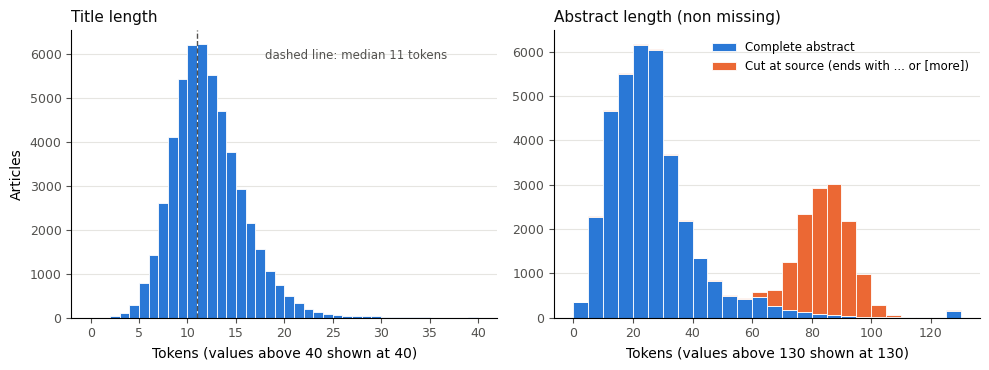

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))
ax1.hist(news["title_len"].clip(upper=40), bins=np.arange(0, 41), color=BLUE, edgecolor="white", linewidth=0.6)
ax1.axvline(news["title_len"].median(), color=MUTED, linestyle="--", linewidth=1)
ax1.text(news["title_len"].median() + 7, ax1.get_ylim()[1] * 0.9, f"dashed line: median {news['title_len'].median():.0f} tokens", color=MUTED, fontsize=8.5)
ax1.set_title("Title length", loc="left", fontsize=11, color=INK)
ax1.set_xlabel("Tokens (values above 40 shown at 40)")
ax1.set_ylabel("Articles")

bins = np.arange(0, 131, 5)
clipped = abstracts["abstract_len"].clip(upper=130)
ax2.hist([clipped[~abstracts["cut_marker"]], clipped[abstracts["cut_marker"]]], bins=bins, stacked=True,
         color=[BLUE, ORANGE], edgecolor="white", linewidth=0.6,
         label=["Complete abstract", "Cut at source (ends with ... or [more])"])
ax2.set_title("Abstract length (non missing)", loc="left", fontsize=11, color=INK)
ax2.set_xlabel("Tokens (values above 130 shown at 130)")
ax2.legend(frameon=False, fontsize=8.5, loc="upper right")
for ax in (ax1, ax2):
    ax.grid(axis="y", color="#e6e5e1", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=MUTED, labelsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_5_4_text_lengths.png", dpi=200, bbox_inches="tight")
plt.show()